本 notebook 是 [M05.1 神经网络基础](../notes/01-neural-network-fundamentals.qmd) 的实例讲解。

1. 1. 两层 MLP 的手写反向传播
2. 2. 损失、似然与数值稳定性
3. 3. 初始化如何影响信号传播
4. 4. 训练小 MLP 与固定线性基线

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

运行前安装已声明依赖：`uv sync --locked --extra perf --extra data --extra dl`。本例使用 CPU，不需外部数据或预训练权重。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.special import logsumexp
from sklearn.linear_model import LinearRegression
from torch import nn

from semiai.plotting import BLUE, GRAY, ORANGE, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. 两层 MLP 的手写反向传播

按数组形状写出前向和各参数梯度，与 PyTorch 自动微分逐项对齐；这里只用自动微分作为参照，计算图机制在下一章展开。

In [2]:
torch.set_num_threads(1)
torch.manual_seed(42)
X = rng.normal(size=(7, 3))
target = rng.normal(size=(7, 1))
W1 = rng.normal(0, 0.3, (3, 5))
b1 = np.zeros(5)
W2 = rng.normal(0, 0.3, (5, 1))
b2 = np.zeros(1)
h = np.tanh(X @ W1 + b1)
prediction = h @ W2 + b2
loss = np.mean((prediction - target) ** 2)
dout = 2 * (prediction - target) / len(X)
gW2 = h.T @ dout
gb2 = dout.sum(axis=0)
dz = (dout @ W2.T) * (1 - h * h)
gW1 = X.T @ dz
gb1 = dz.sum(axis=0)
parameters = [torch.tensor(a, dtype=torch.float64, requires_grad=True) for a in [W1, b1, W2, b2]]
a, c, b, d = parameters
out = torch.tanh(torch.tensor(X) @ a + c) @ b + d
reference = ((out - torch.tensor(target)) ** 2).mean()
reference.backward()
for name, manual, parameter in zip(
    ["W1", "b1", "W2", "b2"], [gW1, gb1, gW2, gb2], parameters, strict=True
):
    print(name, "梯度最大差:", np.max(np.abs(manual - parameter.grad.numpy())))
    assert np.allclose(manual, parameter.grad.numpy(), atol=1e-12)
print("loss:", loss, reference.item())

W1 梯度最大差: 6.938893903907228e-18
b1 梯度最大差: 6.938893903907228e-18
W2 梯度最大差: 5.551115123125783e-17
b2 梯度最大差: 2.7755575615628914e-17
loss: 0.4089700856155347 0.4089700856155347


读法：链式法则先从输出误差传播到隐藏层，再对 batch 求和；PyTorch Linear 的权重布局是 out×in，和这里 NumPy 的 in×out 约定不同。

## 2. 损失、似然与数值稳定性

检查高斯负对数似然与 MSE 的关系，并比较极端 logit 下稳定 BCE 的有限输出。

In [3]:
residual = rng.normal(size=100)
sigma = 0.4
mse = np.mean(residual**2)
nll = 0.5 * np.log(2 * np.pi * sigma * sigma) + mse / (2 * sigma * sigma)
print("MSE:", mse, "给定 sigma 的高斯平均 NLL:", nll)
logit = torch.tensor([-1000.0, 1000.0, -10.0, 10.0], dtype=torch.float64)
y = torch.tensor([1.0, 0.0, 0.0, 1.0], dtype=torch.float64)
stable = nn.functional.binary_cross_entropy_with_logits(logit, y, reduction="none")
manual = np.logaddexp(0, logit.numpy()) - y.numpy() * logit.numpy()
print("稳定 BCE:", stable.numpy())
assert np.allclose(stable.numpy(), manual)
logits = np.array([[1000.0, 1001.0, 999.0]])
log_prob = logits - logsumexp(logits, axis=1, keepdims=True)
print("稳定 softmax 概率和:", np.exp(log_prob).sum())

MSE: 0.7946648297169709 给定 sigma 的高斯平均 NLL: 2.485975394196051
稳定 BCE: [1.00000000e+03 1.00000000e+03 4.53988992e-05 4.53988992e-05]
稳定 softmax 概率和: 0.9999999999999518


读法：固定同方差高斯下 MSE 与 NLL 的最优均值一致，但 sigma 决定概率尺度；分类直接使用 logits 可避免先 sigmoid 再 log 的溢出与精度损失。

## 3. 初始化如何影响信号传播

只改变权重方差，在相同宽度的 ReLU 链上记录二阶矩；这不是精确动力学理论，而是独立近似的数值示意。

init         He         large         small
depth                                      
1      1.022558  7.859225e+00  5.388942e-02
2      1.209371  6.120635e+01  3.079940e-03
3      1.411212  4.413405e+02  1.605847e-04
4      1.125194  4.304258e+03  8.272031e-06
5      0.863591  3.398462e+04  5.031597e-07
6      0.857364  2.117968e+05  1.665521e-08
7      0.776490  1.754106e+06  9.691787e-10
8      0.961472  1.491637e+07  3.012308e-11
9      0.824441  1.700662e+08  1.138367e-12
10     0.713150  1.809809e+09  5.811748e-14


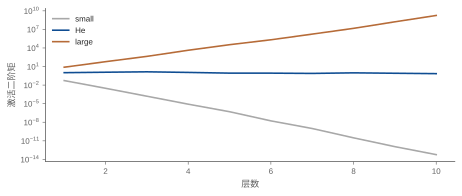

In [4]:
width = 64
input_signal = rng.normal(size=(256, width))
rows = []
for name, std in [("small", 0.04), ("He", np.sqrt(2 / width)), ("large", 0.5)]:
    h = input_signal.copy()
    for depth in range(1, 11):
        weight = rng.normal(0, std, (width, width))
        h = np.maximum(h @ weight, 0)
        rows.append([name, depth, np.mean(h * h)])
table = pd.DataFrame(rows, columns=["init", "depth", "second moment"])
print(table.pivot(index="depth", columns="init", values="second moment"))
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for (name, group), color in zip(
    table.groupby("init", sort=False), [GRAY, BLUE, ORANGE], strict=True
):
    ax.semilogy(group.depth, group["second moment"], color=color, label=name)
ax.set(xlabel="层数", ylabel="激活二阶矩")
ax.legend()
fig.tight_layout()
plt.show()

读法：He 初始化使用约 2/fan_in 的方差补偿 ReLU 截断；有限宽度、均值与相关性仍会引入波动，保持二阶矩也不等于所有 Jacobian 奇异值接近一。

## 4. 训练小 MLP 与固定线性基线

在合成正弦回归上运行完整的最小前向、反向和更新循环，输出独立网格误差。工程化训练状态在 M05.3 继续。

In [5]:
torch.manual_seed(42)
x = np.linspace(-1, 1, 80)[:, None]
y = np.sin(np.pi * x) + rng.normal(0, 0.05, x.shape)
xt = torch.tensor(x, dtype=torch.float32)
yt = torch.tensor(y, dtype=torch.float32)
model = nn.Sequential(nn.Linear(1, 24), nn.Tanh(), nn.Linear(24, 1))
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
history = []
for _ in range(500):
    optimizer.zero_grad(set_to_none=True)
    prediction = model(xt)
    loss = nn.functional.mse_loss(prediction, yt)
    loss.backward()
    optimizer.step()
    history.append(loss.item())
grid = np.linspace(-1, 1, 250)[:, None]
truth = np.sin(np.pi * grid)
with torch.no_grad():
    prediction = model(torch.tensor(grid, dtype=torch.float32)).numpy()
baseline = LinearRegression().fit(x, y).predict(grid)
print("训练首末 MSE:", history[0], history[-1])
print(
    "独立无噪声网格 MSE: MLP",
    np.mean((prediction - truth) ** 2),
    "linear",
    np.mean((baseline - truth) ** 2),
)
assert history[-1] < history[0]

训练首末 MSE: 0.3920336663722992 0.002723599085584283
独立无噪声网格 MSE: MLP 0.00012435860550258124 linear 0.19926746107931154


读法：这个单种子合成实例展示非线性表达与优化过程，不能推断 MLP 在真实材料数据上普遍优于线性模型；训练模式、数据划分和恢复状态在后续章完善。

## 小结

神经网络学习的是非线性复合表示。损失定义观测假设，反向传播高效计算链式法则，初始化控制初始信号尺度。把形状与导数核验清楚，再追训练收敛，才能理解网络何时有效、何时只是数值上在运行。